# Capítulo 2 · Métodos basados en valores

**Lectura:** pp. 31–50; §§2.1–2.5. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch2).

**Idea central:** podemos aprender cuánto conviene cada acción y elegir las de mayor valor, propagando información mediante las ecuaciones de Bellman.

## Resumen

En §2.1 se distinguen el valor de un estado, el valor de una acción y su ventaja respecto a la política. Las ecuaciones de Bellman descomponen un problema de largo plazo en recompensa inmediata y valor del siguiente estado. Evaluar una política fija usa un promedio sobre sus acciones; buscar la política óptima introduce un máximo.

Con modelo conocido, §2.2 presenta iteración de valor, iteración de políticas y RTDP. La primera aplica repetidamente el operador de optimalidad; la segunda alterna evaluación y mejora. RTDP concentra el trabajo en estados relevantes para el problema. En el caso finito descontado, la contracción de Bellman da una razón precisa para la convergencia. El espacio de estados puede seguir siendo demasiado grande para calcularlo todo.

Cuando solo tenemos muestras, §2.3 compara Monte Carlo y diferencias temporales. Monte Carlo espera al retorno observado; TD usa una estimación del futuro como parte de su objetivo, operación llamada bootstrap. TD puede actualizar antes y reducir varianza, pero incorpora errores de su estimación. Los retornos de varios pasos, TD($\lambda$) y las trazas de elegibilidad distribuyen crédito entre distintos horizontes.

SARSA (§2.4) actualiza usando la siguiente acción realmente elegida por la política de comportamiento. Q-learning (§2.5) usa el máximo estimado sobre acciones siguientes. Esta diferencia explica su carácter on-policy y off-policy, respectivamente: Q-learning puede aprender sobre una política greedy mientras recoge datos exploratorios.

La aproximación funcional permite reemplazar tablas enormes por redes. DQN combina aprendizaje de Q con replay y una red objetivo. Reutilizar experiencias mejora el aprovechamiento de datos; una red objetivo cambia más despacio que la red entrenada. Estas técnicas son útiles frente a la combinación problemática de aproximación funcional, bootstrap y aprendizaje off-policy, la llamada tríada mortal. Las garantías tabulares no se trasladan automáticamente al caso neuronal.

El máximo de estimaciones ruidosas introduce sobreestimación. Double Q separa selección y evaluación; Double DQN traslada la idea al caso neuronal. El capítulo también recorre replay priorizado, arquitecturas dueling, noisy nets, retornos de varios pasos, Rainbow y BBF. Son combinaciones de decisiones estadísticas y de ingeniería, no sustitutos del principio de Bellman. Finalmente, HER reutiliza trayectorias fallidas como ejemplos de metas que sí se alcanzaron, recalculando las recompensas correspondientes.

## Ecuaciones esenciales

$$
Q^\pi(s,a)=\mathbb{E}[r_t+\gamma V^\pi(s_{t+1})|s_t=s,a_t=a],
\qquad
A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s).
$$

Q-learning tabular:

$$
Q(s,a)\leftarrow Q(s,a)+\alpha
\left[r+\gamma(1-d)\max_b Q(s',b)-Q(s,a)\right].
$$

$d=1$ indica un terminal real. En SARSA el máximo se reemplaza por $Q(s',a')$, con $a'\sim\pi(\cdot|s')$. Un límite artificial de tiempo no equivale necesariamente a un terminal del problema: hay que definir qué retorno queremos estimar.

## Experimento 2 · Aprender Bellman mediante muestras

**Pregunta:** ¿puede Q-learning aproximarse al resultado de un planificador que conoce el modelo?

Usamos una cadena con siete estados: 0 y 6 son terminales, se empieza cada episodio en un estado interior aleatorio y se evalúa desde el estado 3. Hay acciones izquierda/derecha y una probabilidad de 0.15 de ejecutar la dirección contraria. Entrar en 6 da recompensa 1; las demás transiciones no terminales de origen dan −0.01. Después de terminar no se reciben más recompensas.

El planificador calcula $Q^*$ con el modelo exacto. El agente aprende únicamente de transiciones, con $\epsilon=0.25$, $\gamma=0.95$ y tasa por visita $N(s,a)^{-0.6}$. Se comparan 20 ejecuciones de 16.000 transiciones reales.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 2
~~~

**Métricas:** RMSE entre Q y $Q^*$ sobre pares no terminales, y valor exacto de la política greedy aprendida desde el estado 3. El evaluador conoce el modelo; el aprendiz no lo consulta.

**Qué observar:** el error disminuye y la política puede llegar al valor óptimo antes de que Q sea muy preciso. Para elegir bien basta con ordenar correctamente las acciones relevantes. Los resultados guardados alcanzan el valor óptimo aproximado 0.8166, con error de Q pequeño pero no nulo.

**Modificación:** compara varias probabilidades de deslizamiento o reduce la exploración. Una única ejecución no permite concluir que un cambio de hiperparámetro sea mejor.

**Límite:** este ejemplo es tabular; no prueba estabilidad de DQN ni reproduce la tríada mortal. Tampoco justifica trasladar su tasa de aprendizaje sin cambios a una red.



## Para el grupo

1. ¿Por qué SARSA puede preferir una ruta segura mientras sigue explorando?
2. ¿Cuál es la diferencia entre error de Q y pérdida de rendimiento de la política?
3. ¿Por qué una red objetivo ayuda pero no ofrece por sí sola una garantía universal?

**Conexión:** el capítulo 3 usará estimaciones de valor para mejorar directamente una política parametrizada.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 2
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 2: Q-learning por muestras frente al óptimo de Bellman."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import (cadena, iteracion_valor, evaluar_politica, guardar, curva,
                    greedy_aleatorio, filas_finales, resumen_muestra)

def ejecutar(out, seed=2026, replicas=20, pasos=16000):
    p, r = cadena()
    gamma = .95
    vstar, qstar = iteracion_valor(p, r, gamma)
    checkpoints = np.arange(0, pasos+1, 200)
    error = np.empty((replicas, len(checkpoints)))
    valor = np.empty_like(error)
    finales = []
    for k in range(replicas):
        rng = np.random.default_rng(seed+k)
        q = np.zeros_like(qstar)
        visits = np.zeros_like(q)
        s = int(rng.integers(1, 6))
        j = 0
        for t in range(pasos+1):
            if t % 200 == 0:
                error[k, j] = np.sqrt(np.mean((q[1:-1]-qstar[1:-1])**2))
                valor[k, j] = evaluar_politica(p, r, q.argmax(axis=1), gamma)[3]
                j += 1
            if t == pasos:
                break
            a = int(rng.integers(2)) if rng.random() < .25 else greedy_aleatorio(q[s], rng)
            ns = int(rng.choice(7, p=p[s, a]))
            done = ns in (0, 6)
            visits[s, a] += 1
            alpha = visits[s, a]**(-.6)
            target = r[s, a, ns] + gamma*(not done)*q[ns].max()
            q[s, a] += alpha*(target-q[s, a])
            s = int(rng.integers(1, 6)) if done else ns
        finales.append(q)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    curva(ax[0], checkpoints, error, "Q-learning")
    ax[0].set(xlabel="Transiciones reales", ylabel="RMSE frente a Q*", title="Error de estimación")
    curva(ax[1], checkpoints, valor, "Política greedy aprendida")
    ax[1].axhline(vstar[3], color="black", ls="--", label="Óptimo por programación dinámica")
    ax[1].set(xlabel="Transiciones reales", ylabel="V(s=3), evaluación exacta", title="Calidad de la política")
    ax[1].legend()
    metrics = {"gamma": gamma, "slip": .15, "epsilon": .25, "pasos": pasos,
               "valor_optimo_inicio": float(vstar[3]), "rmse_final": resumen_muestra(error[:, -1]),
               "valor_final": resumen_muestra(valor[:, -1])}
    return guardar(out, dict(pasos=checkpoints, rmse=error, valor=valor, qstar=qstar,
                            q_final=np.array(finales)), filas_finales("RMSE Q-learning", error[:, -1]),
                   metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 2: completado en 4.91 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap02



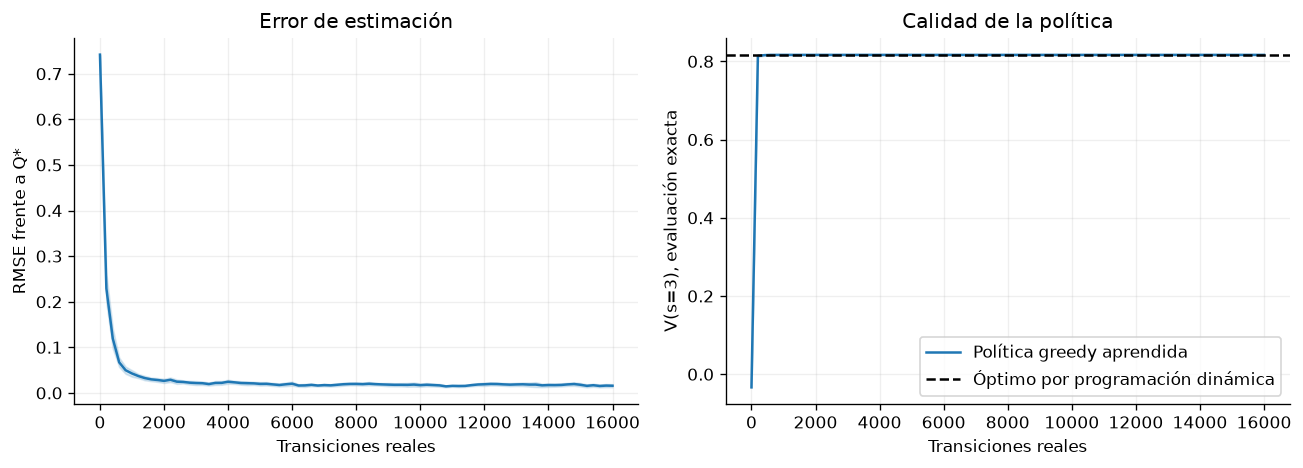

{
  "gamma": 0.95,
  "slip": 0.15,
  "epsilon": 0.25,
  "pasos": 16000,
  "valor_optimo_inicio": 0.8166195128234138,
  "rmse_final": {
    "media": 0.015769913738370202,
    "ic95_aprox_semianchura": 0.0032108400796087267
  },
  "valor_final": {
    "media": 0.8166195128236943,
    "ic95_aprox_semianchura": 4.9921715471057503e-17
  }
}


In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

pasos (81,)
rmse (20, 81)
valor (20, 81)
qstar (7, 2)
q_final (20, 7, 2)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.